In [34]:
import numpy as np
# PP hinh thang
#thuật toán 14: Phương pháp hình thang
'''
Require:
    -f: hàm số cần tính tích phân
    -a: cận dưới
    -b: cận trên
    -n: số khoảng chia (n>0)
    -M2: chặn trên đạo hàm cấp 2
    -h: độ rộng khoảng chia
Ensure:
    -trả về giá trị tuple[I, E]: giá trị tích phân xấp xỉ I và cận sai số E
'''
def trapezoid(f, a, b, n, M2):
  if n<=0:
        print('Số khoảng chia phải lớn hơn 0')
        return None
  sum=0
  h=(b-a)/n #dòng 1 thuật toán 14
  for i in range(1,n):
      sum+=f(a+i*h)
  I=(h/2)*(f(a)+2*sum+f(b)) #dòng 5 thuật toán 14
  E=M2*(b-a)**3/(12*n**2)
  return I, E

# PP hcn

def midpoint(f, a, b, n, M2) -> tuple[float, float]: #(I, E)
    """
    tên thuật toán: Phương pháp hình chữ nhật trung tâm kèm cận sai số
    require:
        f: hàm số cần tính tích phân (callable function)
        a: cận dưới của tích phân (float hoặc int)
        b: cận trên của tích phân (float hoặc int)
        n: số khoảng chia (số nguyên dương)
        M2: chặn trên của giá trị tuyệt đối đạo hàm cấp 2 ( dùng để đánh giá sai số)
    ensure:
        tuple(I_rec, E): giá trị xấp xỉ tích phân và cận sai số lí thuyết
    """
    #xử lí tình huống biên:
    if not callable(f):
        raise(Exception('tham so f phai la mot ham so hop le'))
    if a >= b:
        raise(Exception('can duoi a phai nho hon can tren a'))
    if not isinstance(n, int):
        raise(Exception('so khoang chia n phai la so nguyen duong'))
    if M2<0:
        raise(Exception('can sai so M2 phai la so ko am'))
    h = (b-a)/n #dòng 1- thuật toán 13
    Sum_val = 0.0
    for i in range(n): #dòng 2 - thuật toán 13
        midpoint_val = ((a+i*h) + (a + (i+1)*h))/2 #dòng 3 - thuật toán 13
        Sum_val += f(midpoint_val) #dòng 4 - thuật toán 13
    I = h*Sum_val #dòng 6 - thuật toán 13
    E = (M2 * (b-a) * (h**2))/24
    return I, E #dòng7 - thuật toán 13
# PP simpson 1/3 do n chẵn

def simpson(f, a: float, b: float, n: int, M4: float) -> tuple[float, float]:
    """
    Thuật toán 16: Tính tích phân xác định bằng phương pháp Simpson 1/3.

    Require (Đầu vào):
        f (callable): Hàm số f(x) liên tục trên [a, b].
        a (float): Cận dưới tích phân.
        b (float): Cận trên tích phân.
        n (int,  n >= 2): Số khoảng chia n chẵn.
        M4 (float): Chặn trên đạo hàm bậc 4 của f(x) trên [a, b].

    Ensure (Đầu ra):
        tuple[float, float]: (I_Simpson, E) trong đó:
            - I_Simpson (float): Giá trị tích phân xấp xỉ.
            - E (float): Cận sai số lý thuyết.
    """
    # Kiểm tra điều kiện biên
    if n <= 0:
        raise ValueError("Lỗi biên: Số đoạn chia n phải là số nguyên dương.")
    if n % 2 != 0:
        raise ValueError(f"Lỗi biên: Phương pháp Simpson yêu cầu n phải là số chẵn .")
    if M4 < 0:
        raise ValueError("Lỗi biên: Chặn trên đạo hàm M4 không thể âm.")
    if a > b:
        raise ValueError("Lỗi biên: Cận dưới a không thể lớn hơn cận trên b.")

    # BẮT ĐẦU THUẬT TOÁN

    h = (b - a) / n # Dòng 1 - Thuật toán 16: Tính h

    # Khởi tạo các biến tổng tích lũy
    sum1 = 0.0 # Tổng các vị trí i chẵn (nhân với 2)
    sum2 = 0.0 # Tổng các vị trí i lẻ (nhân với 4)

    # Định nghĩa hàm tính x_i = a + i*h
    def x(i):
        return a + i * h

    for i in range(1, n):     # Dòng 2 - Thuật toán 16
        if i % 2 == 0: # Dòng 3 - Thuật toán 16
            sum1 += f(x(i)) # Dòng 4 - Thuật toán
        else:
            sum2 += f(x(i)) # Dòng 6 - Thuật toán 16

    I = (h / 3) * (f(a) + 2 * sum1 + 4 * sum2 + f(b))  # Dòng 9 - Thuật toán 16
    E = (M4 * (b - a)**5) / (180 * (n**4))
    return I, E  # Dòng 10 - Thuật toán 16
# SV6 - chạy thử với n = 2,4,8...1024 ; đưa ra bảng sai số
# lấy hàm f(x) = 1/(1+x) cận chạy từ 0 đến 1
"""Hàm dưới dấu tích phân f(x) = 1/(1+x).
Require: x là số thực, x > -1.
Ensure: trả về giá trị f(x).
"""
def f(x):
    return 1 / (1 + x)
a, b = 0, 1 # cận trên và dưới
exact_val = np.log(2) # Tích phân đúng của 1/(1+x) trên [0,1] là ln(2)
M2 = 2 # giá trị max của f''(x) trên [0,1]
M4 = 24 # giá trị max của f''''(x) trên [0,1]
# tạo vòng lặp cho số khoảng chia
n_values = []
for i in range (1,11):
  n = 2**i
  n_values.append(n)
#Khởi tạo mảng lưu dữ liệu sai số , khoảng chia
h_array = []
err_mid_actual, err_mid_theory = [], []
err_trap_actual, err_trap_theory = [], []
err_simp_actual, err_simp_theory = [], []
# In khung bảng
print(" "*20 + " BẢNG SAI SỐ " + " "*20)
print(f"{'n':<6}{'h':<10}{'HCN thuc':<14}{'HCN LT':<14}{'Thang thuc':<14}{'Thang LT':<14}{'Simp thuc':<14}{'Simp LT':<14}")
for n in n_values:
    h = (b - a) / n
    h_array.append(h)

    # 1. Gọi hàm tính toán
    val_mid, bound_mid = midpoint(f, a, b, n, M2)
    val_trap, bound_trap = trapezoid(f, a, b, n, M2)
    val_simp, bound_simp = simpson(f, a, b, n, M4)

    # 2. Tính sai số thực tế (Trị tuyệt đối của [Kết quả code - Kết quả đúng])
    e_mid = abs(val_mid - exact_val)
    e_trap = abs(val_trap - exact_val)
    e_simp = abs(val_simp - exact_val)

    # 3. Lưu vào mảng
    err_mid_actual.append(e_mid)
    err_mid_theory.append(bound_mid)

    err_trap_actual.append(e_trap)
    err_trap_theory.append(bound_trap)

    err_simp_actual.append(e_simp)
    err_simp_theory.append(bound_simp)

    # 4. In ra một dòng của bảng (độ rộng mỗi cột khớp với dòng tiêu đề)
    print(f"{n:<6}{h:<10.6f}{e_mid:<14.2e}{bound_mid:<14.2e}{e_trap:<14.2e}{bound_trap:<14.2e}{e_simp:<14.2e}{bound_simp:<14.2e}")


                     BẢNG SAI SỐ                     
n     h         HCN thuc      HCN LT        Thang thuc    Thang LT      Simp thuc     Simp LT       
2     0.500000  7.43e-03      2.08e-02      1.52e-02      4.17e-02      1.30e-03      8.33e-03      
4     0.250000  1.93e-03      5.21e-03      3.88e-03      1.04e-02      1.07e-04      5.21e-04      
8     0.125000  4.87e-04      1.30e-03      9.75e-04      2.60e-03      7.35e-06      3.26e-05      
16    0.062500  1.22e-04      3.26e-04      2.44e-04      6.51e-04      4.72e-07      2.03e-06      
32    0.031250  3.05e-05      8.14e-05      6.10e-05      1.63e-04      2.97e-08      1.27e-07      
64    0.015625  7.63e-06      2.03e-05      1.53e-05      4.07e-05      1.86e-09      7.95e-09      
128   0.007812  1.91e-06      5.09e-06      3.81e-06      1.02e-05      1.16e-10      4.97e-10      
256   0.003906  4.77e-07      1.27e-06      9.54e-07      2.54e-06      7.28e-12      3.10e-11      
512   0.001953  1.19e-07      3.18e-0

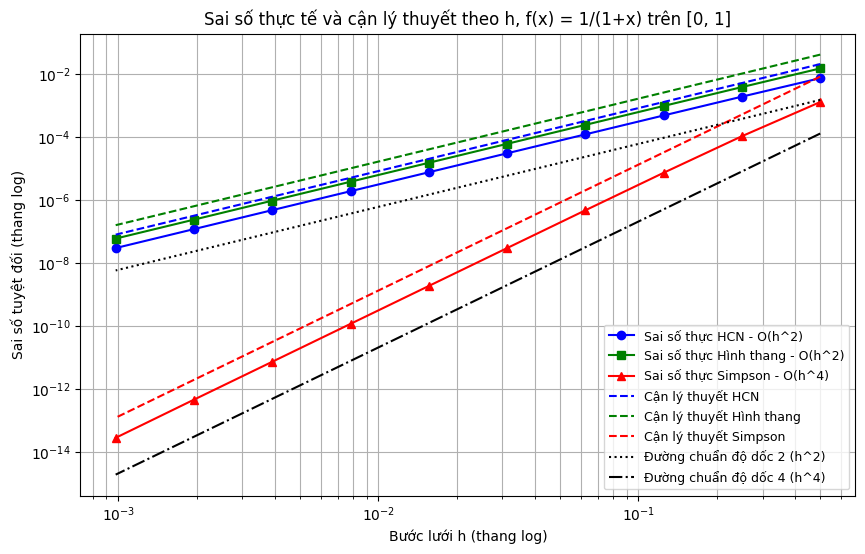

In [37]:
import matplotlib.pyplot as plt
ref2 = []
ref4 = []
for h in h_array:
    ref2.append(0.1 * err_trap_actual[0] * (h / h_array[0])**2)
    ref4.append(0.1 * err_simp_actual[0] * (h / h_array[0])**4)

plt.figure(figsize=(10, 6))

# Sai số thực tế: nét liền, có điểm nút
plt.loglog(h_array, err_mid_actual,  'bo-', label='Sai số thực HCN - O(h^2)')
plt.loglog(h_array, err_trap_actual, 'gs-', label='Sai số thực Hình thang - O(h^2)')
plt.loglog(h_array, err_simp_actual, 'r^-', label='Sai số thực Simpson - O(h^4)')

# Cận sai số lý thuyết: nét đứt
plt.loglog(h_array, err_mid_theory,  'b--', label='Cận lý thuyết HCN')
plt.loglog(h_array, err_trap_theory, 'g--', label='Cận lý thuyết Hình thang')
plt.loglog(h_array, err_simp_theory, 'r--', label='Cận lý thuyết Simpson')

# Đường chuẩn độ dốc
plt.loglog(h_array, ref2, 'k:',  label='Đường chuẩn độ dốc 2 (h^2)')
plt.loglog(h_array, ref4, 'k-.', label='Đường chuẩn độ dốc 4 (h^4)')

# Tên trục, tiêu đề, lưới, chú thích
plt.xlabel('Bước lưới h (thang log)')
plt.ylabel('Sai số tuyệt đối (thang log)')
plt.title('Sai số thực tế và cận lý thuyết theo h, f(x) = 1/(1+x) trên [0, 1]')
plt.grid(True, which='both')
plt.legend(fontsize=9, loc='lower right')

plt.savefig('do_thi_sai_so_nhom5.png', dpi=300)
plt.show()

In [36]:
import numpy as np
#Kiểm chứng hội tụ
print("Bậc hội tụ thực nghiệm  p = log2(e_n / e_2n)")
print(f"{'n -> 2n':<16}{'HCN':<12}{'Hình thang':<14}{'Simpson':<12}")
print(" " * 60)
for i in range(len(n_values) - 1):
    p_mid = np.log2(err_mid_actual[i] / err_mid_actual[i + 1])
    p_trap = np.log2(err_trap_actual[i] / err_trap_actual[i + 1])
    p_simp = np.log2(err_simp_actual[i] / err_simp_actual[i + 1])
    ten = str(n_values[i]) + " -> " + str(n_values[i + 1])
    print(f"{ten:<16}{p_mid:<12.6f}{p_trap:<14.6f}{p_simp:<12.6f}")

# So sánh ss thực với cận LT
print(" " * 60)
print("SO sánh sai số thực với cận lý thuyết ")
print(" " * 60)
print(f"{'n':<8}{'Cận/Thực HCN':<16}{'Cận/Thực Thang':<16}{'Cận/Thực Simp':<16}{'Thực <= Cận':<14}")
for i in range(len(n_values)):
    ti_so_mid = err_mid_theory[i] / err_mid_actual[i]
    ti_so_trap = err_trap_theory[i] / err_trap_actual[i]
    ti_so_simp = err_simp_theory[i] / err_simp_actual[i]

    if err_mid_actual[i] <= err_mid_theory[i] and err_trap_actual[i] <= err_trap_theory[i] and err_simp_actual[i] <= err_simp_theory[i]:
        ket_luan = "Đúng"
    else:
        ket_luan = "VI PHẠM"
    print(f"{n_values[i]:<8}{ti_so_mid:<16.6f}{ti_so_trap:<16.6f}{ti_so_simp:<16.6f}{ket_luan:<14}")

# Kiểm chứng
print(" " * 60)
print("Kiểm chứng : (2*I_hcn + I_thang)/3 = I_Simpson(2n)")
print(" " * 60)
print(f"{'n':<8}{'(2*HCN+Thang)/3':<20}{'Simpson 2n':<20}{'Sai khác':<12}")
sai_khac_max = 0
for n in n_values:
    I_mid, E_mid = midpoint(f, a, b, n, M2)        # I_hcn với n khoảng
    I_trap, E_trap = trapezoid(f, a, b, n, M2)     # I_thang với n khoảng
    I_simp, E_simp = simpson(f, a, b, 2 * n, M4)   # Simpson với 2n khoảng

    I_tron = (2 * I_mid + I_trap) / 3              # công thức cần kiểm chứng
    sai_khac = abs(I_tron - I_simp)

    if sai_khac > sai_khac_max:
        sai_khac_max = sai_khac
    print(f"{n:<8}{I_tron:<20.6f}{I_simp:<20.6f}{sai_khac:<12.2e}")
if sai_khac_max < 1e-12:
    print("Kết luận: hai giá trị trùng nhau (sai khác là do sai số làm tròn của máy) .")
else:
    print("Kết luận: không trùng, cần kiểm tra lại code.")

Bậc hội tụ thực nghiệm  p = log2(e_n / e_2n)
n -> 2n         HCN         Hình thang    Simpson     
                                                            
2 -> 4          1.947351    1.969882      3.602655    
4 -> 8          1.985686    1.991817      3.860839    
8 -> 16         1.996333    1.997904      3.960111    
16 -> 32        1.999077    1.999473      3.989594    
32 -> 64        1.999769    1.999868      3.997369    
64 -> 128       1.999942    1.999967      3.999343    
128 -> 256      1.999986    1.999992      3.999887    
256 -> 512      1.999996    1.999998      3.998834    
512 -> 1024     1.999999    1.999999      4.029513    
                                                            
SO sánh sai số thực với cận lý thuyết 
                                                            
n       Cận/Thực HCN    Cận/Thực Thang  Cận/Thực Simp   Thực <= Cận   
2       2.802856        2.743728        6.423777        Đúng          
4       2.702414        2.687042        4